In [31]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers
from keras.models import Sequential
from keras.layers import (
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    Rescaling,
    RandomRotation,
    RandomContrast,
    RandomZoom,
    BatchNormalization,
    Input
    )


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow:', tf.__version__)
print('GPU(s):', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU(s): []


### Reading Data

In [10]:
data_dir=r"C:\Users\win 11d\Desktop\machin\sabzejo\j1\mri_data (1)"

train_path=os.path.join(data_dir,"Training")
test_path=os.path.join(data_dir,"Testing")

class_names=os.listdir(train_path)
class_names

['glioma', 'meningioma', 'notumor', 'pituitary']

### Showing All Classes

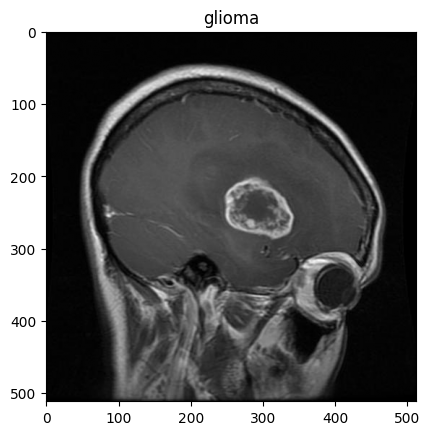

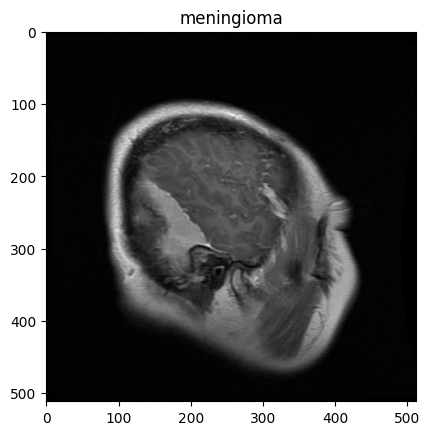

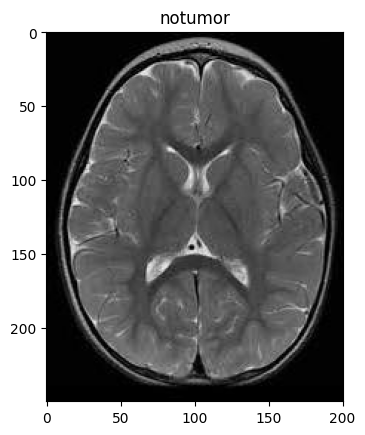

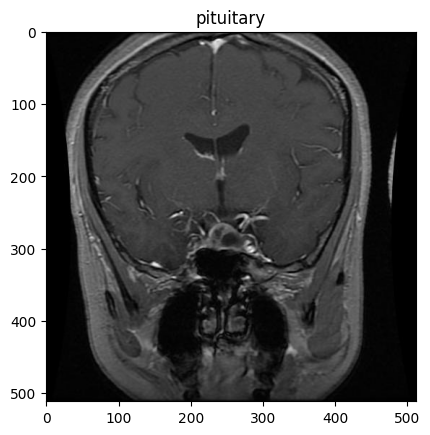

In [11]:
class_names=os.listdir(train_path)

for index,class_name in enumerate(class_names):

    class_path=os.path.join(train_path , class_name)
    images=os.listdir(class_path)
    img_random=random.choice(images)
    img_path=os.path.join(class_path,img_random)
    image=plt.imread(img_path)

    plt.imshow(image, cmap='gray')
    plt.title(class_name)
    plt.show()


### Creating Dataset

In [12]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

class_names = list(train_ds.class_names)



Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.


In [9]:
train_ds.class_names

['glioma', 'meningioma', 'notumor', 'pituitary']

In [7]:
class_names

['glioma', 'meningioma', 'notumor', 'pituitary']

In [13]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names,
    shuffle=False,
)

Found 1600 files belonging to 4 classes.


In [14]:
print('Class indices:', dict(enumerate(class_names)))
print('Batches — train/val/test:',
      tf.data.experimental.cardinality(train_ds).numpy(),
      tf.data.experimental.cardinality(val_ds).numpy(),
      tf.data.experimental.cardinality(test_ds).numpy())

for images, labels in train_ds.take(1):
    print('Image batch shape:', images.shape, '| Label shape:', labels.shape)
    print('Pixel range:', float(tf.reduce_min(images)), float(tf.reduce_max(images)))


Class indices: {0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}
Batches — train/val/test: 140 35 50
Image batch shape: (32, 128, 128, 3) | Label shape: (32,)
Pixel range: 0.0 255.0


### Auto-tune Data

In [15]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


### Data Augmentation

In [16]:
data_augmentation=Sequential(name="data_augmentation")

data_augmentation.add(RandomRotation(0.03))

data_augmentation.add(RandomZoom(0.08))

data_augmentation.add(RandomContrast(0.1))

<Sequential name=data_augmentation, built=False>

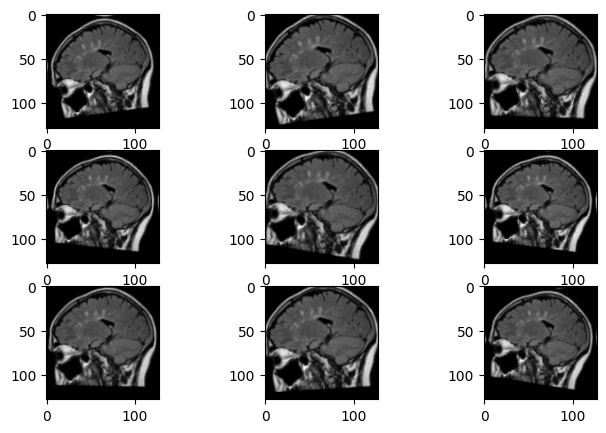

In [17]:
for img , label in train_ds.take(1):

    image3=img[8]
    plt.figure(figsize=(8,5))
    for s in range(9):
        augmented=data_augmentation(tf.expand_dims(image3 , axis=0) , training=True)
        plt.subplot(3 , 3 , s +1)

        plt.imshow(tf.cast(augmented[0],tf.uint8))

### Architecture of Model

In [43]:

model=Sequential()

model.add(Input(shape=(128 , 128 , 3)))

model.add(data_augmentation)

model.add(Rescaling(1/255))

model.add(Conv2D(32 , kernel_size=(3 , 3) ,padding='same',activation='relu'))
model.add(BatchNormalization())
model.add(layers.ReLU())
model.add(MaxPooling2D())
model.add(Dropout(0.2))

model.add(Conv2D(64 , kernel_size=(3 , 3) ,padding='same' ,activation='relu'))
model.add(BatchNormalization())
model.add(layers.ReLU())
model.add(MaxPooling2D())
model.add(Dropout(0.2))

model.add(Conv2D(128 , kernel_size=(3 , 3) , padding='same' , activation='relu'))
model.add(BatchNormalization())
model.add(layers.ReLU())
model.add(MaxPooling2D())
model.add(Dropout(0.2))

model.add(GlobalAveragePooling2D())

model.add(Dense(128 , activation='relu'))

model.add(Dropout(0.3))

model.add(Dense(4 , activation='softmax'))

model.summary()


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_8 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,172 (434.27 KB)

 Trainable params: 110,724 (432.52 KB)

 Non-trainable params: 448 (1.75 KB)

>- parameters of conv: (kernel_width * kernel_height * input_channel * + 1) * outputs_filter

In [19]:
(3 * 3 * 3 +1) * 32 #conv 1

896

In [20]:
(3 * 3 * 32 +1 )*64 #conv 2

18496

In [21]:
(3 * 3 * 64 +1) * 128 #conv 3

73856

In [22]:
(128 *128) + 128 #hidden 1

16512

In [23]:
(128 * 4) + 4 #output

516

In [24]:
16* 16* 128

32768

### Compile

In [44]:
from keras.optimizers import Adam
adam = Adam(learning_rate=1e-4) # 0.0003

model.compile(
    optimizer=adam,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

### EarlyStopping

In [45]:
from keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor='val_loss' ,
                  patience=4 ,
                  verbose=1 ,
                  restore_best_weights=True)

### Fit

In [46]:
history=model.fit(train_ds,
          validation_data=val_ds,
          epochs=20,
          callbacks=early_stopping,
          verbose=1
          )

Epoch 1/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 248ms/step - accuracy: 0.5232 - loss: 1.1064 - val_accuracy: 0.2393 - val_loss: 1.3872
Epoch 2/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 34s 246ms/step - accuracy: 0.6609 - loss: 0.8591 - val_accuracy: 0.3866 - val_loss: 1.3608
Epoch 3/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 34s 246ms/step - accuracy: 0.6871 - loss: 0.7865 - val_accuracy: 0.5277 - val_loss: 1.2337
Epoch 4/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 35s 248ms/step - accuracy: 0.7074 - loss: 0.7458 - val_accuracy: 0.6768 - val_loss: 1.0395
Epoch 5/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 255ms/step - accuracy: 0.7295 - loss: 0.7068 - val_accuracy: 0.7196 - val_loss: 0.8825
Epoch 6/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 257ms/step - accuracy: 0.7393 - loss: 0.6681 - val_accuracy: 0.5357 - val_loss: 0.9824
Epoch 7/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 258ms/step - accuracy: 0.7549 - loss: 0.6314 - val_accuracy: 0.5080 - val_loss: 0.9912
Epoch 8/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 258ms/step - accuracy: 0.7676 - loss: 0

### Accuracy Diagram

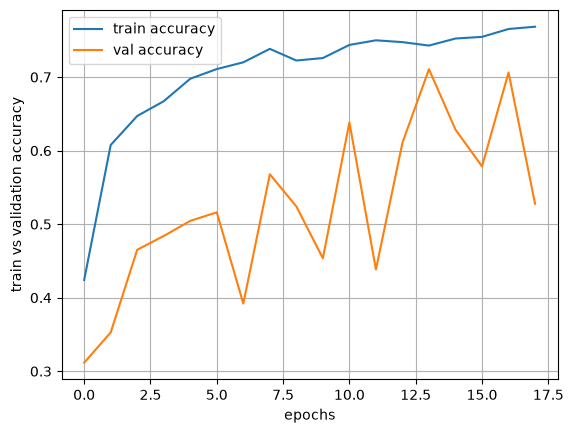

In [29]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],label='train accuracy')
plt.plot(history.history['val_accuracy'],label='val accuracy')
plt.xlabel("epochs")
plt.ylabel("train vs validation accuracy")
plt.grid()
plt.legend()
plt.show()

### Loss Diagram

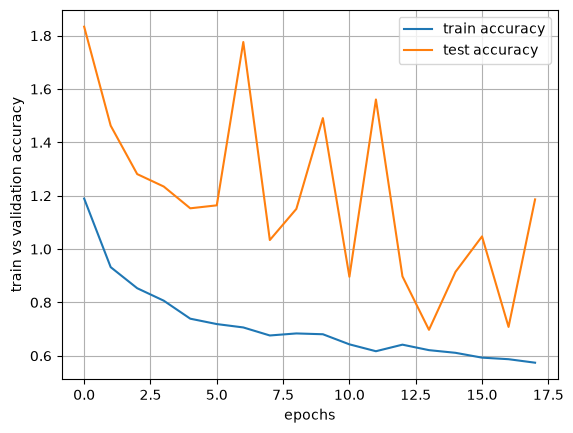

In [30]:
plt.plot(history.history['loss'],label='train accuracy')
plt.plot(history.history['val_loss'],label='test accuracy')
plt.xlabel("epochs")
plt.ylabel("train vs validation accuracy")
plt.grid()
plt.legend()
plt.show()

# Evaluation

In [2]:
test_loss, test_accuracy = model.evaluate(test_ds)
print(f'Test loss: {test_loss:.4f} | Test accuracy: {test_accuracy:.2%}')

NameError: name 'model' is not defined

In [32]:
real_label=np.concatenate([label.numpy()  for _, label in test_ds])
prediction_pro=model.predict(test_ds)
prediction=np.argmax(prediction_pro,axis=1)

50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step


In [1]:
print(classification_report(
    real_label, prediction,
    labels=list(range(len(class_names))),
    target_names=class_names,
))

NameError: name 'classification_report' is not defined

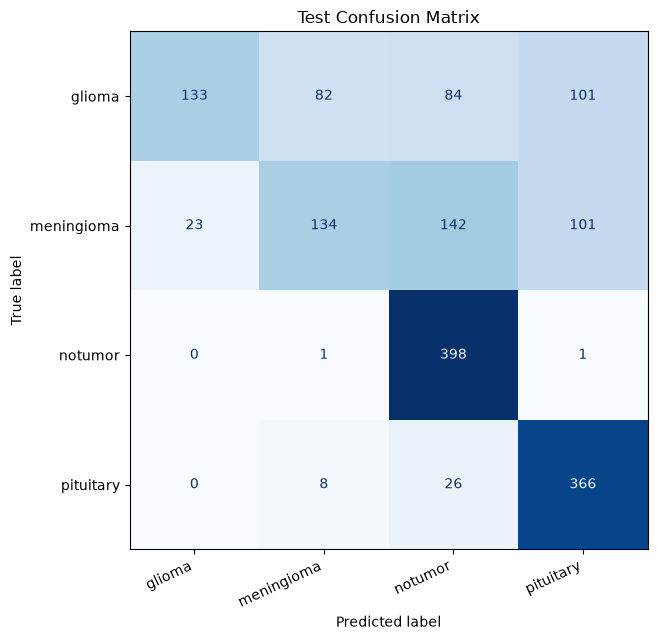

In [34]:
cm = confusion_matrix(real_label, prediction, labels=list(range(len(class_names))))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False,
)
plt.xticks(rotation=25, ha='right')
plt.title('Test Confusion Matrix')
plt.tight_layout()
plt.show()
